# Resultados phantom revisados — UG con $(Q=\alpha\rho^\beta)$

Este notebook **no vuelve a ejecutar el barrido ODE**. Trabaja únicamente con
`Resultados_Phantom_Full_Revisados.csv` y presenta los resultados consolidados
para exposición.

Modelo:
$
p=\omega\rho,\qquad Q=\alpha\rho^\beta,\qquad \omega<-1,
$
$
3H^2=\rho+\alpha\rho^\beta,\qquad
\dot\rho=-\frac{3H(1+\omega)\rho}
{1+\alpha\beta\rho^{\beta-1}},
\qquad
\dot H=-\frac{1+\omega}{2}\rho.
$


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_CANDIDATES = [
    Path("Resultados_Phantom_Full_Revisados.csv"),
    Path("/Resultados_Phantom_Full_Revisados.csv"),
    Path("data/processed/Resultados_Phantom_Full_Revisados.csv"),
]

DATA_PATH = next(
    (path for path in DATA_CANDIDATES if path.exists()),
    None,
)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Copia Resultados_Phantom_Full_Revisados.csv "
        "junto al notebook o a data/processed/."
    )

df = pd.read_csv(DATA_PATH)
print("Filas phantom:", len(df))
print("Omegas:", sorted(df["omega"].unique()))


FileNotFoundError: Copia Resultados_Phantom_Full_Revisados.csv junto al notebook o a data/processed/.

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ---------------------------------------------------------
# Localizar la raíz del proyecto
# ---------------------------------------------------------

CURRENT_PATH = Path.cwd().resolve()

PROJECT_ROOT = None

for candidate in [
    CURRENT_PATH,
    *CURRENT_PATH.parents,
]:
    if (
        (candidate / "src").exists()
        and (candidate / "data").exists()
    ):
        PROJECT_ROOT = candidate
        break


if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "No se pudo localizar la raíz del proyecto. "
        "Debe existir una carpeta src/ y una carpeta data/."
    )


print(
    "Raíz del proyecto:",
    PROJECT_ROOT,
)


# ---------------------------------------------------------
# Buscar el CSV revisado
# ---------------------------------------------------------

DATA_CANDIDATES = [
    PROJECT_ROOT
    / "Resultados_Phantom_Full_Revisados.csv",

    PROJECT_ROOT
    / "data"
    / "processed"
    / "Resultados_Phantom_Full_Revisados.csv",

    PROJECT_ROOT
    / "data"
    / "processed"
    / "barotropic_parameter_space"
    / "Resultados_Phantom_Full_Revisados.csv",
]


DATA_PATH = next(
    (
        path
        for path in DATA_CANDIDATES
        if path.exists()
    ),
    None,
)


if DATA_PATH is None:
    searched_paths = "\n".join(
        str(path)
        for path in DATA_CANDIDATES
    )

    raise FileNotFoundError(
        "No se encontró "
        "Resultados_Phantom_Full_Revisados.csv.\n\n"
        "Rutas revisadas:\n"
        f"{searched_paths}"
    )


# ---------------------------------------------------------
# Cargar resultados
# ---------------------------------------------------------

df = pd.read_csv(
    DATA_PATH
)


print(
    "CSV utilizado:",
    DATA_PATH,
)

print(
    "Filas phantom:",
    len(df),
)

print(
    "Omegas:",
    sorted(
        df["omega"].unique()
    ),
)

Raíz del proyecto: /Users/macbook/Usach/TesisxD/cosmo_singularities
CSV utilizado: /Users/macbook/Usach/TesisxD/cosmo_singularities/data/processed/Resultados_Phantom_Full_Revisados.csv
Filas phantom: 2325
Omegas: [np.float64(-1.4), np.float64(-1.2), np.float64(-1.05)]


## 1. Conteos finales por régimen

In [5]:
counts = (
    df.groupby(["omega", "final_behavior"])
      .size()
      .rename("count")
      .reset_index()
)

display(counts)


,omega,final_behavior,count
0,-1.40,diffusion_driven_infinite_time_rip,158
1,-1.40,little_rip,140
2,-1.40,type_i_big_rip,417
3,-1.40,type_iv_D_boundary,60
4,-1.20,diffusion_driven_infinite_time_rip,158
5,-1.20,little_rip,140
6,-1.20,type_i_big_rip,417
7,-1.20,type_iv_D_boundary,60
8,-1.05,diffusion_driven_infinite_time_rip,158
9,-1.05,little_rip,140


## 2. Correcciones analíticas al diagnóstico puramente numérico

In [6]:
corrected = df[
    df["analytic_correction"].fillna("").ne("")
][
    [
        "omega",
        "alpha",
        "beta",
        "numerical_label_original",
        "final_behavior",
        "analytic_correction",
    ]
]

print("Puntos corregidos:", len(corrected))
display(corrected)


Puntos corregidos: 88


,omega,alpha,beta,numerical_label_original,final_behavior,analytic_correction
212,-1.40,1.550000,-0.666667,regular_expansion,diffusion_driven_infinite_time_rip,H crece asintóticamente aunque el diagnóstico ...
213,-1.40,1.754167,-0.666667,regular_expansion,diffusion_driven_infinite_time_rip,H crece asintóticamente aunque el diagnóstico ...
214,-1.40,1.958333,-0.666667,regular_expansion,diffusion_driven_infinite_time_rip,H crece asintóticamente aunque el diagnóstico ...
215,-1.40,2.162500,-0.666667,regular_expansion,diffusion_driven_infinite_time_rip,H crece asintóticamente aunque el diagnóstico ...
216,-1.40,2.366667,-0.666667,regular_expansion,diffusion_driven_infinite_time_rip,H crece asintóticamente aunque el diagnóstico ...
...,...,...,...,...,...,...
1820,-1.05,3.183333,-0.333333,regular_expansion,diffusion_driven_infinite_time_rip,H crece asintóticamente aunque el diagnóstico ...
1821,-1.05,3.387500,-0.333333,regular_expansion,diffusion_driven_infinite_time_rip,H crece asintóticamente aunque el diagnóstico ...
1822,-1.05,3.591667,-0.333333,regular_expansion,diffusion_driven_infinite_time_rip,H crece asintóticamente aunque el diagnóstico ...
1823,-1.05,3.795833,-0.333333,regular_expansion,diffusion_driven_infinite_time_rip,H crece asintóticamente aunque el diagnóstico ...


## 3. Tabla de regiones

Para $(\rho_0=1)$:

$
\beta<0,\ \alpha>0,\ D_0=1+\alpha\beta<0
\Rightarrow
\text{rip asintótico dominado por difusión}.
$

$
\alpha<0,\ \beta>1
\Rightarrow
D(\rho_D)=0
\Rightarrow
\text{Tipo IV}.
$

$
\alpha>0,\ \beta\ge2
\Rightarrow
\text{Little Rip}.
$

Las ramas phantom físicas restantes terminan en Big Rip.


## 4. Mapa revisado para $\omega$ = -1.2

/var/folders/7v/mpqjvkxx00lf3_k_1wpn9jsw0000gn/T/ipykernel_11271/1978848907.py:22: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  encoded = matrix.replace(label_to_code).to_numpy(dtype=float)


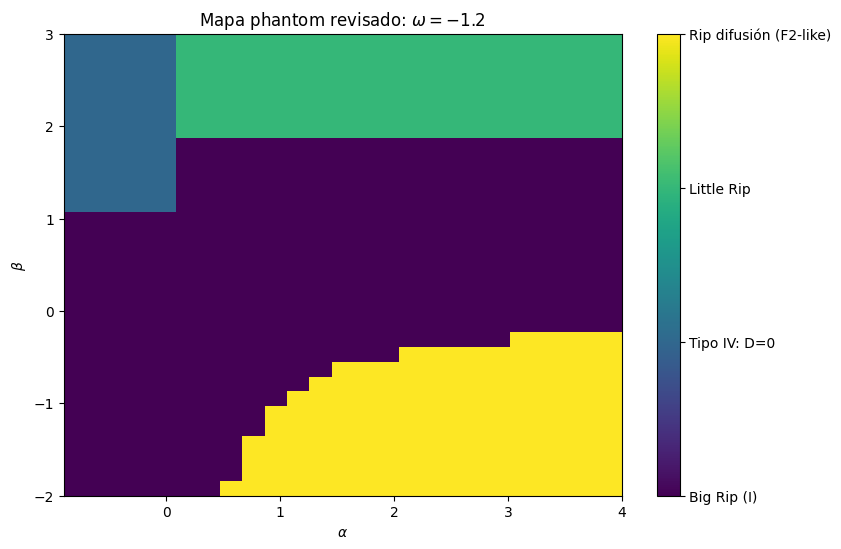

In [7]:
omega = -1.2
subset = df[np.isclose(df["omega"], omega)].copy()

labels = [
    "type_i_big_rip",
    "type_iv_D_boundary",
    "little_rip",
    "diffusion_driven_infinite_time_rip",
]
label_to_code = {label: i for i, label in enumerate(labels)}

matrix = (
    subset.pivot(
        index="beta",
        columns="alpha",
        values="final_behavior",
    )
    .sort_index()
    .sort_index(axis=1)
)

encoded = matrix.replace(label_to_code).to_numpy(dtype=float)

alphas = matrix.columns.to_numpy(dtype=float)
betas = matrix.index.to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=(9, 6))
image = ax.imshow(
    encoded,
    origin="lower",
    aspect="auto",
    extent=[
        alphas.min(),
        alphas.max(),
        betas.min(),
        betas.max(),
    ],
    interpolation="nearest",
)

ax.set_xlabel(r"$\alpha$")
ax.set_ylabel(r"$\beta$")
ax.set_title(r"Mapa phantom revisado: $\omega=-1.2$")

cb = fig.colorbar(image, ax=ax)
cb.set_ticks(range(len(labels)))
cb.set_ticklabels(
    [
        "Big Rip (I)",
        "Tipo IV: D=0",
        "Little Rip",
        "Rip difusión (F2-like)",
    ]
)

plt.show()


## 5. Frontera $(\beta=2)$

Para $(\alpha>0,\beta>1,\rho\to\infty)$,
$
\dot\rho\sim
\frac{\sqrt3\,\gamma}{\beta\sqrt{\alpha}}
\rho^{2-\beta/2}.
$

Por lo tanto:
$
\beta<2\Rightarrow t_s<\infty,
\qquad
\beta\ge2\Rightarrow t\to\infty.
$


In [8]:
comp = df[
    (df["alpha"] > 0)
    & (df["rho_limit"] == "diverges")
    & (df["finite_time"].notna())
].copy()

comp["prediction_finite"] = comp["beta"] < 2
comp["observed_finite"] = comp["finite_time"].astype(bool)
comp["agreement"] = (
    comp["prediction_finite"]
    == comp["observed_finite"]
)

print("Puntos comparados:", len(comp))
print("Acuerdo:", comp["agreement"].mean())
print("Desacuerdos:", (~comp["agreement"]).sum())


Puntos comparados: 1386
Acuerdo: 1.0
Desacuerdos: 0


## 6. F2

$
(\omega,\alpha,\beta)=(-1.2,4,-1),
\qquad
Q=\frac4\rho,
\qquad
D=1-\frac4{\rho^2}.
$

Con $(\rho_0=1)$,
$
D_0=-3<0
\quad\Rightarrow\quad
\dot\rho<0.
$

Así:
$
\rho\to0,\quad
Q\to\infty,\quad
H\to\infty,\quad
\dot H\to0^+,\quad
a\to\infty,
\quad t\to\infty.
$

La relación exacta es
$
a(\rho)=
\rho^{5/3}
\exp\left[
\frac{10}{3}
(\rho^{-2}-1)
\right].
$

Asintóticamente:
$
\rho\sim(0.2598t)^{-2/3},
\quad
H\sim0.737t^{1/3},
\quad
\dot H\sim0.246t^{-2/3},
\quad
\ln a\sim0.553t^{4/3}.
$


In [9]:
f2 = df[
    np.isclose(df["omega"], -1.2)
    & np.isclose(df["alpha"], 4.0)
    & np.isclose(df["beta"], -1.0)
]

display(
    f2[
        [
            "omega",
            "alpha",
            "beta",
            "D0",
            "numerical_label_original",
            "final_behavior",
            "time_limit",
            "rho_limit",
            "a_limit",
            "H_limit",
            "Hdot_limit",
            "confidence",
        ]
    ]
)


,omega,alpha,beta,D0,numerical_label_original,final_behavior,time_limit,rho_limit,a_limit,H_limit,Hdot_limit,confidence
949,-1.2,4.0,-1.0,-3.0,diffusion_driven_infinite_time_rip,diffusion_driven_infinite_time_rip,infinite,zero,diverges,diverges,zero,0.95


## 7. Principales Conclusiones

1. El régimen phantom presenta cuatro destinos robustos.
2. La frontera $(\beta=2)$ separa Big Rip y Little Rip para $(\alpha>0)$.
3. $(\alpha<0,\beta>1)$ conduce a una frontera $(D=0)$ de Tipo IV.
4. Existe una región completa $(\beta<0,\alpha>0,D_0<0)$ en la cual
   $(\rho\to0)$ pero la difusión produce $(Q,H,a\to\infty)$.
5. F2 es un representante particularmente limpio de esta región.
6. Por ahora la region F2 se llamara **régimen asintótico dominado por difusión**
   o **diffusion-driven infinite-time rip**, aun no se debe clasificar como una nueva singularidad.
